# Single-polymer L1 sparse autoencoder
Train on processed intensities from `data/all_spectra.csv` (no log conversion).
Change `POLYMER` below. Uses a row-level 80/20 holdout after removing exact
spectral duplicates; source/particle IDs are unavailable, so validation is exploratory.
Requires the packages in the project's `requirements.txt`.


In [6]:
from pathlib import Path
import sys, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/all_spectra.csv").exists() and (p / "models").is_dir())
sys.path.insert(0, str(ROOT))
from models import SparseAutoencoder

POLYMER = "Polystyrene"
HIDDEN, L1, LR, EPOCHS, PATIENCE = 32, 1e-3, 1e-3, 500, 50
torch.manual_seed(42)
torch.set_num_threads(2)


In [7]:
df = pd.read_csv(ROOT / "data/all_spectra.csv", index_col=0)
columns = sorted([c for c in df.columns if c != "polymer"], key=float)
wavenumbers = np.array(columns, dtype=float)
selected = df.loc[df["polymer"].eq(POLYMER), columns]
selected = selected.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
if len(selected) < 10:
    raise ValueError(f"Need at least 10 valid, distinct spectra for {POLYMER}.")
raw = torch.tensor(selected.to_numpy(dtype=np.float32))
order = torch.randperm(len(raw))
cut = int(0.8 * len(raw))
train_raw, val_raw = raw[order[:cut]], raw[order[cut:]]
scale = train_raw.std().clamp_min(1e-8)  # One training-only global scale.
train, val = train_raw / scale, val_raw / scale
model = SparseAutoencoder(train.shape[1], HIDDEN, L1, train.mean(0))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
print(f"{POLYMER}: {len(train)} train / {len(val)} validation; {train.shape[1]} channels")


Polystyrene: 150 train / 38 validation; 535 channels


In [8]:
history, best_mse, best_state, stale = [], float("inf"), None, 0
for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    reconstruction, z = model(train)
    losses = model.loss(train, reconstruction, z)
    losses["loss"].backward()
    optimizer.step()
    model.eval()
    with torch.no_grad():
        val_mse = (model(val)[0] - val).square().mean().item()
    history.append((losses["reconstruction_loss"].item(), val_mse))
    if val_mse < best_mse:
        best_mse, best_state, stale = val_mse, copy.deepcopy(model.state_dict()), 0
    else:
        stale += 1
    if stale >= PATIENCE:
        break
model.load_state_dict(best_state)
print(f"Completed {len(history)} epochs; restored epoch {np.argmin(np.array(history)[:, 1]) + 1}.")


Completed 379 epochs; restored epoch 329.


Validation MSE: 0.237734 | Mean-spectrum baseline: 0.625407
Average active features: 13.6 / 32


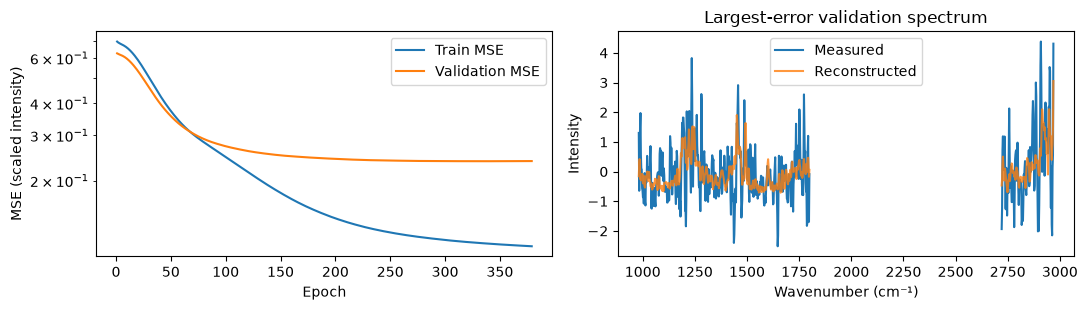

In [9]:
model.eval()
with torch.no_grad():
    reconstructed, z = model(val)
    prediction = reconstructed * scale
    mse = (prediction - val_raw).square().mean().item()
    baseline = (train_raw.mean(0) - val_raw).square().mean().item()
print(f"Validation MSE: {mse:.6g} | Mean-spectrum baseline: {baseline:.6g}")
print(f"Average active features: {(z > 0).float().sum(1).mean().item():.1f} / {HIDDEN}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(np.arange(1, len(history) + 1), history, label=["Train MSE", "Validation MSE"])
axes[0].set(xlabel="Epoch", ylabel="MSE (scaled intensity)", yscale="log")
axes[0].legend()
i = (prediction - val_raw).square().mean(1).argmax().item()
gaps = np.flatnonzero(np.diff(wavenumbers) > 2 * np.median(np.diff(wavenumbers))) + 1
plot_x = np.insert(wavenumbers, gaps, np.nan)  # Leave unmeasured regions blank.
axes[1].plot(plot_x, np.insert(val_raw[i].numpy(), gaps, np.nan), label="Measured")
axes[1].plot(plot_x, np.insert(prediction[i].numpy(), gaps, np.nan), label="Reconstructed", alpha=0.8)
axes[1].set(xlabel="Wavenumber (cm⁻¹)", ylabel="Intensity", title="Largest-error validation spectrum")
axes[1].legend()
plt.tight_layout()
plt.show()


## Inspect hidden features
The heatmap and activation frequencies use held-out spectra. Set `NEURON` to
an integer to inspect its decoder pattern and strongest measured examples;
`None` selects the highest-mean-activation neuron. Patterns require validation
before assigning chemical meaning. Saved runs retain source row IDs.


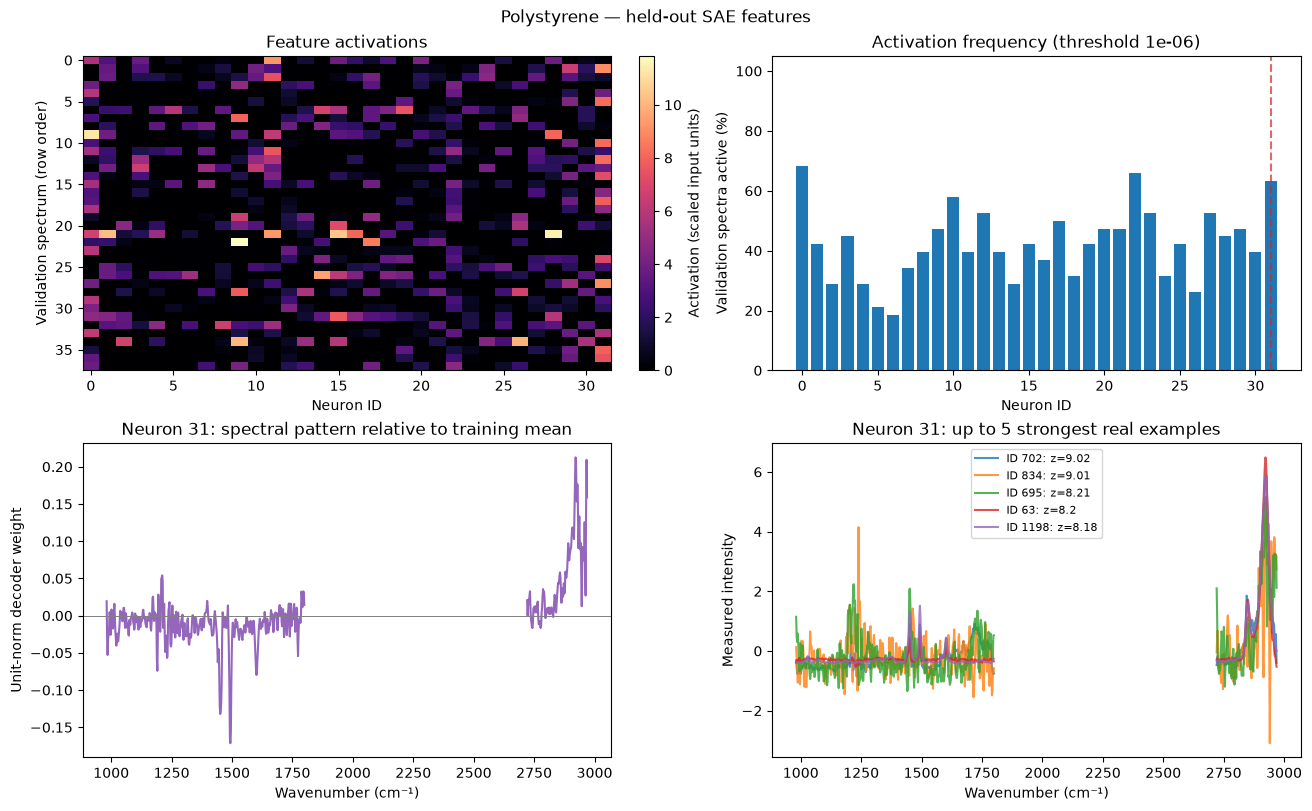

In [10]:
from experiments.sae_visualization import plot_sae_run, compare_sae_runs

NEURON = None  # For example: 5. Neuron IDs are local to each trained model.
THRESHOLD = 1e-6
RUNS = ROOT / "experiments/results/sae"
RUNS.mkdir(parents=True, exist_ok=True)
run_path = RUNS / f"{POLYMER.lower().replace(' ', '_')}.npz"
model.eval()
with torch.no_grad():
    _, activations = model(val)
np.savez_compressed(
    run_path, polymer=POLYMER, wavenumbers=wavenumbers,
    activations=activations.cpu().numpy(),
    decoder_features=model.decoder_weight.detach().cpu().numpy(),
    spectra=val_raw.cpu().numpy(),
    sample_ids=selected.index.to_numpy()[order[cut:].numpy()].astype(str),
    scale=scale.item(), l1_lambda=L1,
    mean_spectrum=model.mean_spectrum.detach().cpu().numpy() * scale.item(),
)
fig = plot_sae_run(run_path, neuron=NEURON, threshold=THRESHOLD)
fig.savefig(run_path.with_suffix(".png"), dpi=150)
plt.show()


## Compare polymer trainings
Change `POLYMER` above and rerun to add another training. Each polymer's latest
validation results are saved in `experiments/results/sae`, including across
kernel restarts. Rerunning a polymer replaces its previous snapshot.
Neuron numbers do not align between models, and activation magnitudes use
each model's own input scale; compare activation patterns and sparsity.


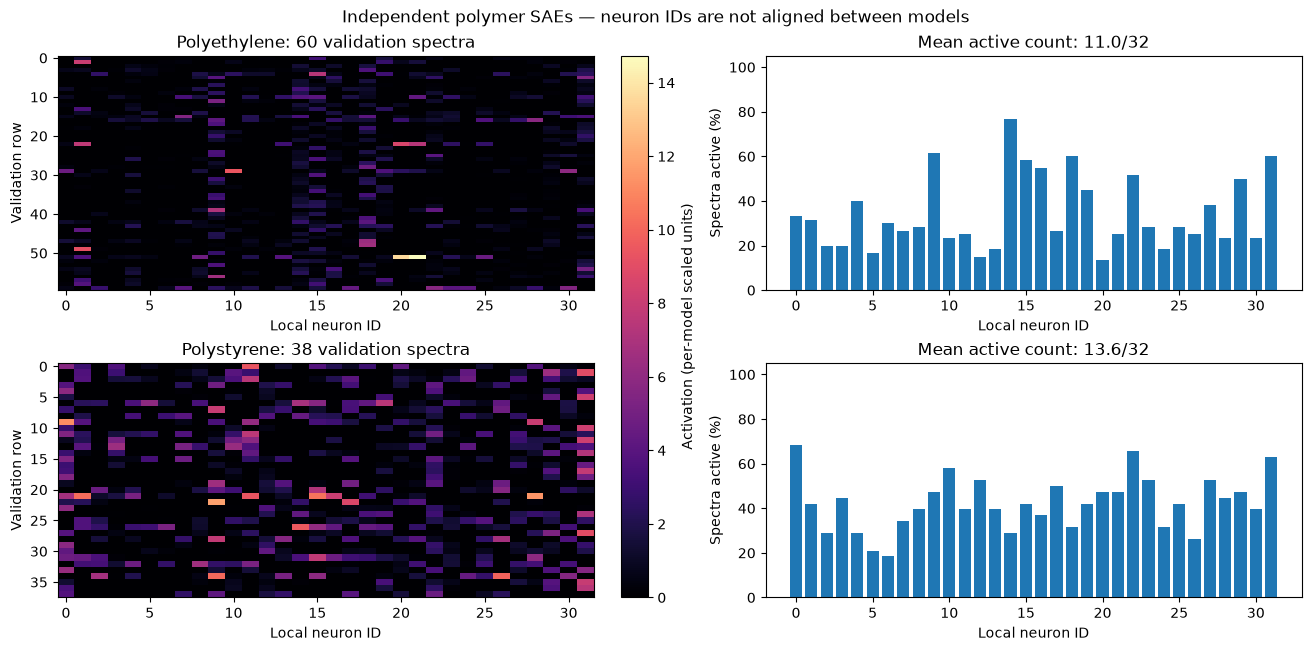

In [11]:
fig = compare_sae_runs(RUNS, threshold=THRESHOLD)
fig.savefig(RUNS / "polymer_comparison.png", dpi=150)
plt.show()
